## Лабораторная работа №1 | Вариант 6

Выполнил: Дробышев Егор, М8О-314БВ-24

### 1. Numpy

In [6]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [7]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [8]:
np.diag(np.arange(1, 5), k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

в первом случае 9, тк второй параметр это начальное значение отсчета
а во втором получим np.sum() и там будет 2 параметра: a, axis -> выведется 10

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [18]:
a = np.array([1, 2, 2, 3, 5])
b = np.array([2, 3, 3, 4, 2])
values, counts = np.unique(np.concatenate([a, b]), return_counts=True)
print(f'most recent value is {values[counts.argmax()]}. count {counts.max()} times')

most recent value is 2. count 4 times


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [ ]:
np.seterr(all='ignore')

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [11]:
def generator():
    for i in range(10):
        yield i

np.fromiter(generator(), dtype=int)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [12]:
rng = np.random.default_rng(42)
values = rng.random(10)
values.sort()
values

array([0.09417735, 0.12811363, 0.43887844, 0.45038594, 0.69736803,
       0.7611397 , 0.77395605, 0.78606431, 0.85859792, 0.97562235])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [13]:
rng = np.random.default_rng(42)
cartesian = rng.random((10, 2))
x, y = cartesian[:, 0], cartesian[:, 1]
polar = np.column_stack([np.hypot(x, y), np.arctan2(y, x)])
polar

array([[0.88973156, 0.51584563],
       [1.10612502, 0.68214621],
       [0.98015731, 1.47456395],
       [1.0941804 , 0.80150622],
       [0.46825271, 1.29366315],
       [0.99819062, 1.19020435],
       [1.04474828, 0.90677675],
       [0.49825053, 0.47357778],
       [0.55824451, 0.11456822],
       [1.04114037, 0.65190816]])

9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [14]:
pixel = np.dtype([('x', np.int32), ('y', np.int32), ('r', np.uint8), ('g', np.uint8), ('b', np.uint8)])
pixels = np.array([(0, 0, 255, 0, 0), (10, 20, 0, 128, 255)], dtype=pixel)
print(pixels)
print(pixels['r'])

[( 0,  0, 255,   0,   0) (10, 20,   0, 128, 255)]
[255   0]


10. Как конвертировать тип массив от float32 в int32 in place?

In [17]:
floats = np.arange(10, dtype=np.float32)
ints = floats.view(np.int32)

ints[:] = floats
print(floats.dtype, ints, ints.dtype)

float32 [0 1 2 3 4 5 6 7 8 9] int32


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [19]:
import pandas as pd

In [22]:
# Load dataset here
df = pd.read_csv('student_perfomance.csv')
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [25]:
df['Sleep_Hours'].mean()

np.float64(7.029060087785682)

2. Сколько процентов студентов посещают внеклассовые активности?

In [27]:
share = (df['Extracurricular_Activities'] == 'Yes').mean() * 100
share

np.float64(59.60345088542455)

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [28]:
by_gender = df.groupby('Gender')['Exam_Score'].agg(['count', 'mean', 'std'])
by_gender

,count,mean,std
Gender,,,
Female,2793,67.244898,4.054451
Male,3814,67.228894,3.766360


In [29]:
by_gender.loc['Female', 'mean'] - by_gender.loc['Male', 'mean']

np.float64(0.016004409105022432)

среднее у девушек выше на 0.016
НО учитывая std получим, что на самом деле результаты одинаковы в таком случае

4. Выведите 25 и 75 перцентили времени сна студентов

In [30]:
q25, q75 = df['Sleep_Hours'].quantile([0.25, 0.75])
q25, q75

(6.0, 8.0)

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [31]:
long_sleep = df.loc[df['Sleep_Hours'] >= q75, 'Exam_Score']
short_sleep = df.loc[df['Sleep_Hours'] <= q25, 'Exam_Score']

# results
print(f'спят много: n = {len(long_sleep)}, средний балл = {long_sleep.mean():.3f}')
print(f'недосып: n = {len(short_sleep)}, средний балл = {short_sleep.mean():.3f}')
print(f'разница: {long_sleep.mean() - short_sleep.mean():.3f}')

спят много: n = 2486, средний балл = 67.187
недосып: n = 2380, средний балл = 67.281
разница: -0.094


6. Влияет ли физическая активность на результаты экзамена?

In [32]:
print(df.groupby('Physical_Activity')['Exam_Score'].agg(['count', 'mean']).round(3))

                   count    mean
Physical_Activity               
0                     46  67.522
1                    421  66.969
2                   1627  67.185
3                   2545  67.196
4                   1575  67.313
5                    361  67.604
6                     32  68.094


In [33]:
df['Physical_Activity'].corr(df['Exam_Score'])

np.float64(0.027824436180257393)

нет, не влияет

7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [35]:
education = df.dropna(subset=['Parental_Education_Level'])
higher = education['Parental_Education_Level'].isin(['College', 'Postgraduate'])
higher_scores = education.loc[higher, 'Exam_Score']
other_scores = education.loc[~higher, 'Exam_Score']

print(f'с вышкой: n = {len(higher_scores)}, средний балл = {higher_scores.mean():.3f}')
print(f'без вышки: n = {len(other_scores)}, средний балл = {other_scores.mean():.3f}')
print(f'разнциа: {higher_scores.mean() - other_scores.mean():.3f}')

с вышкой: n = 3294, средний балл = 67.575
без вышки: n = 3223, средний балл = 66.894
разнциа: 0.682


в среднем, правда, однако отличие в среднем балле небольшое

8. Как влияет участие родителей на результаты экзаменов

In [36]:
involvement = df.groupby('Parental_Involvement')['Exam_Score'].agg(['count', 'mean'])
involvement

,count,mean
Parental_Involvement,,
High,1908,68.092767
Low,1337,66.358265
Medium,3362,67.098156


в среднем, никак не влияет, хотя при высоком уровне вовлеченности балл выше. нужно рассматривать больше данных и изучать доп критерии

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [37]:
income = df.groupby('Family_Income')['Exam_Score'].agg(['count', 'mean'])
income

,count,mean
Family_Income,,
High,1269,67.842396
Low,2672,66.848428
Medium,2666,67.334959


In [38]:
is_high = df['Family_Income'] == 'High'
high_income = df.loc[is_high, 'Exam_Score'].mean()
other_income = df.loc[~is_high, 'Exam_Score'].mean()
print(f'доход выше среднего: {high_income:.3f}, остальные: {other_income:.3f}, разница: {high_income - other_income:.3f}')

доход выше среднего: 67.842, остальные: 67.091, разница: 0.751


в среднем, балл выше, но не сильно (аналогично прошлому вопросу)

10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [39]:
poor = df[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
poor

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
68,22,98,Medium,High,No,5,69,Low,No,1,Low,High,Public,Negative,4,No,High School,Moderate,Female,69
145,25,73,Medium,High,No,8,53,High,No,0,Low,High,Private,Negative,5,No,Postgraduate,Near,Female,66
165,22,87,High,Low,Yes,7,68,Medium,No,0,Low,Medium,Public,Neutral,2,No,High School,Near,Male,67
175,25,82,Medium,Medium,No,6,86,Medium,No,3,Low,High,Public,Positive,3,No,High School,Near,Female,69
221,9,96,Medium,Medium,Yes,4,82,High,No,0,Low,Medium,Public,Positive,4,No,College,Near,Male,67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6388,25,79,High,Medium,No,6,77,Low,No,2,Low,High,Public,Neutral,3,No,High School,Near,Male,68
6409,21,89,Medium,Medium,No,6,97,Medium,No,1,Low,Medium,Private,Negative,3,No,Postgraduate,Far,Female,68
6446,15,77,High,Medium,Yes,5,65,Low,No,2,Low,Medium,Public,Positive,4,Yes,Postgraduate,Near,Male,65
6490,21,93,Medium,Medium,Yes,8,78,Medium,No,0,Low,Medium,Private,Neutral,3,No,High School,Near,Male,68


In [40]:
print(f"низкий доход без интернета: n = {len(poor)}, доля выше 70 баллов: {(poor['Exam_Score'] > 70).mean():.4f}")

низкий доход без интернета: n = 211, доля выше 70 баллов: 0.0806


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

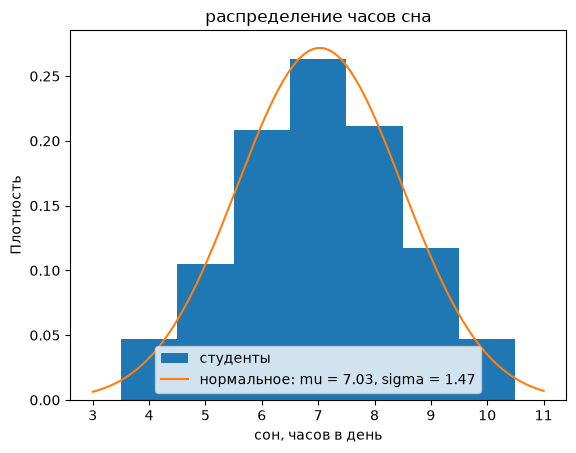

асимметрия: -0.024, эксцесс: -0.504, в пределах одного sigma: 0.684


In [49]:
sleep = df['Sleep_Hours']
mean, std = sleep.mean(), sleep.std()
grid = np.linspace(sleep.min() - 1, sleep.max() + 1, 200)
normal = np.exp(-((grid - mean) ** 2) / (2 * std**2)) / (std * np.sqrt(2 * np.pi))

fig, ax = plt.subplots()
ax.hist(sleep, bins=np.arange(3.5, 11.5), density=True, label='студенты')
ax.plot(grid, normal, label=f'нормальное: mu = {mean:.2f}, sigma = {std:.2f}')
ax.set(title='распределение часов сна', xlabel='сон, часов в день', ylabel='Плотность')
ax.legend()
plt.show()

within_one_std = sleep.between(mean - std, mean + std).mean()
print(f'асимметрия: {sleep.skew():.3f}, эксцесс: {sleep.kurt():.3f}, в пределах одного sigma: {within_one_std:.3f}')

да, примерно нормально. распеделение симметрично, а в пределах sigma лежит 68% студентов

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

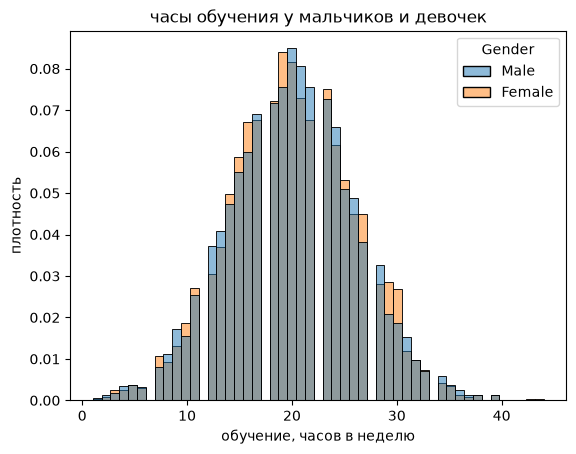

        count    mean    std
Gender                      
Female   2793  20.005  5.997
Male     3814  19.954  5.986


In [50]:
fig, ax = plt.subplots()
sns.histplot(data=df, x='Hours_Studied', hue='Gender', stat='density', common_norm=False, ax=ax)
ax.set(title='часы обучения у мальчиков и девочек', xlabel='обучение, часов в неделю', ylabel='плотность')
plt.show()

print(df.groupby('Gender')['Hours_Studied'].agg(['count', 'mean', 'std']).round(3))

3. Как зависит результат конечного экзамена от результата первого экзамена

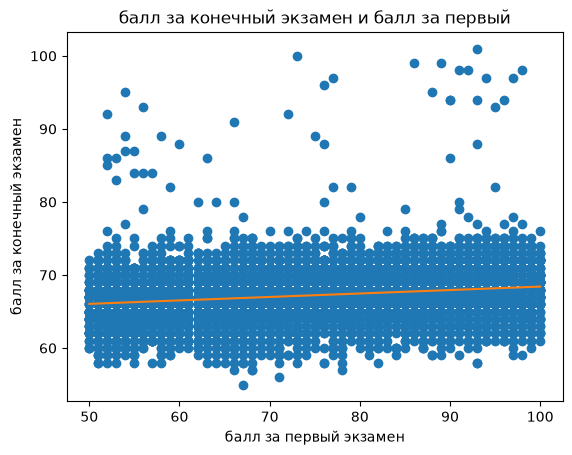

корреляция экзаменов: 0.175, наклон прямой: 0.0473
баллов выше 76: 60


In [51]:
slope, intercept = np.polyfit(df['Previous_Scores'], df['Exam_Score'], 1)
line_x = np.array([df['Previous_Scores'].min(), df['Previous_Scores'].max()])

fig, ax = plt.subplots()
ax.scatter(df['Previous_Scores'], df['Exam_Score'])
ax.plot(line_x, slope * line_x + intercept, color='tab:orange')
ax.set(title='балл за конечный экзамен и балл за первый', xlabel='балл за первый экзамен', ylabel='балл за конечный экзамен')
plt.show()

print(f"корреляция экзаменов: {df['Previous_Scores'].corr(df['Exam_Score']):.3f}, наклон прямой: {slope:.4f}")
print(f"баллов выше 76: {(df['Exam_Score'] > 76).sum()}")

зависимость положительная, но слабая

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

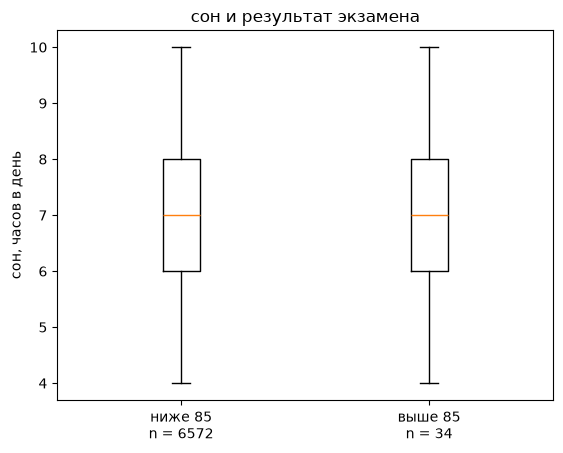

ровно 85 баллов (не вошли): 1
сон ниже 85: среднее = 7.030, медиана = 7
сон выше 85: среднее = 6.882, медиана = 7


In [52]:
below = df.loc[df['Exam_Score'] < 85, 'Sleep_Hours']
above = df.loc[df['Exam_Score'] > 85, 'Sleep_Hours']

fig, ax = plt.subplots()
ax.boxplot([below, above], tick_labels=[f'ниже 85\nn = {len(below)}', f'выше 85\nn = {len(above)}'])
ax.set(title='сон и результат экзамена', ylabel='сон, часов в день')
plt.show()

print(f"ровно 85 баллов (не вошли): {(df['Exam_Score'] == 85).sum()}")
print(f'сон ниже 85: среднее = {below.mean():.3f}, медиана = {below.median():.0f}')
print(f'сон выше 85: среднее = {above.mean():.3f}, медиана = {above.median():.0f}')

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

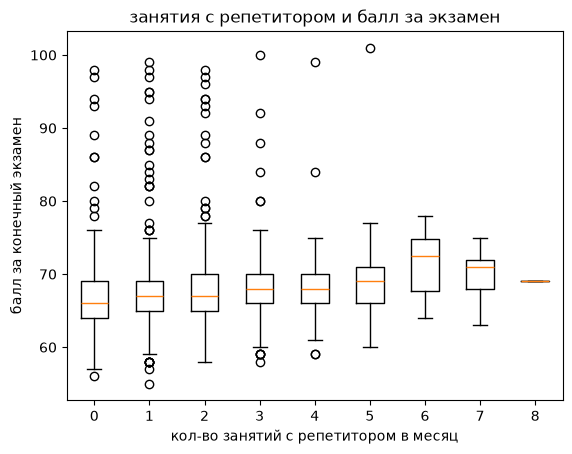

                   count    mean  median
Tutoring_Sessions                       
0                   1513  66.490    66.0
1                   2179  66.980    67.0
2                   1649  67.567    67.0
3                    836  67.895    68.0
4                    301  68.229    68.0
5                    103  69.068    69.0
6                     18  71.667    72.5
7                      7  69.857    71.0
8                      1  69.000    69.0
корреляция Tutoring_Sessions: 0.157


In [54]:
def boxplot_by(column, title, xlabel):
    groups = df.groupby(column)['Exam_Score']
    fig, ax = plt.subplots()
    ax.boxplot([scores for _, scores in groups], tick_labels=[value for value, _ in groups])
    ax.set(title=title, xlabel=xlabel, ylabel='балл за конечный экзамен')
    plt.show()
    print(groups.agg(['count', 'mean', 'median']).round(3))
    print(f"корреляция {column}: {df[column].corr(df['Exam_Score']):.3f}")


boxplot_by('Tutoring_Sessions', 'занятия с репетитором и балл за экзамен', 'кол-во занятий с репетитором в месяц')

скорее правда. но связь слабая, от 0 до 5 занятий балл растет, а далее нельзя сделать выводы по данным и установить зависимость и причинность

6. Как физическая активность влияет на успеваемость?

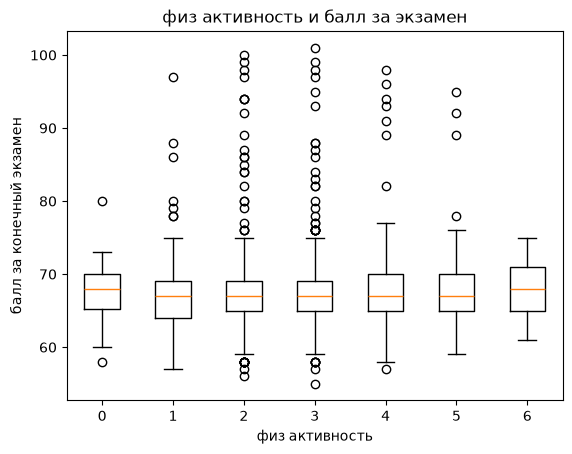

                   count    mean  median
Physical_Activity                       
0                     46  67.522    68.0
1                    421  66.969    67.0
2                   1627  67.185    67.0
3                   2545  67.196    67.0
4                   1575  67.313    67.0
5                    361  67.604    67.0
6                     32  68.094    68.0
корреляция Physical_Activity: 0.028


In [55]:
boxplot_by('Physical_Activity', 'физ активность и балл за экзамен', 'физ активность')

никак. медиана во всех группах примерно равна, а межквартильные размахи также почти совпадают, корреляция низкая

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

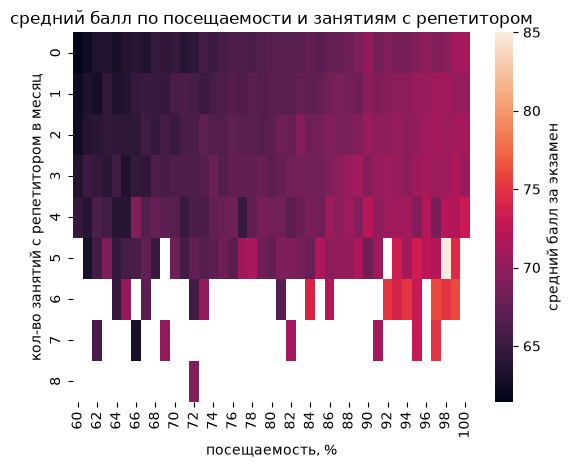

максимум: 5 занятий, посещаемость 98%, средний балл 85.0, n = 2
корреляция посещаемости и балла: 0.581


In [56]:
heatmap = df.pivot_table(values='Exam_Score', index='Tutoring_Sessions', columns='Attendance', aggfunc='mean')

fig, ax = plt.subplots()
sns.heatmap(heatmap, cbar_kws={'label': 'средний балл за экзамен'}, ax=ax)
ax.set(title='средний балл по посещаемости и занятиям с репетитором', xlabel='посещаемость, %', ylabel='кол-во занятий с репетитором в месяц')
plt.show()

sessions, attendance = heatmap.stack().idxmax()
cell = df[(df['Tutoring_Sessions'] == sessions) & (df['Attendance'] == attendance)]
print(f"максимум: {sessions} занятий, посещаемость {attendance}%, средний балл {cell['Exam_Score'].mean():.1f}, n = {len(cell)}")
print(f"корреляция посещаемости и балла: {df['Attendance'].corr(df['Exam_Score']):.3f}")